# Bayesian Cox, Lasso (L1)

L1-regularized version, Laplace prior on the coefficients instead of Gaussian, which pushes weak coefficients to exactly zero. Should in theory do better than plain L2 on high-dimensional survival data since we get feature selection built in.

## Model

Hazard function:
$$h(t|X) = h_0(t) \exp(\beta^T X)$$

Laplace (double exponential) prior for the L1 effect:
$$p(\beta) = \prod_{j=1}^{p} \text{Laplace}(\beta_j | 0, b)$$

Same sparsity mechanism as classical Lasso, just with a Bayesian layer on top: sparse coefficients, credible intervals, handles multicollinearity reasonably well, gives probabilistic predictions instead of point estimates.

In [43]:
# usual imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# PyTorch for Bayesian inference
import torch
import torch.nn as nn

# Survival analysis
from sksurv.metrics import concordance_index_censored, brier_score
from sksurv.util import Surv
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

import warnings
warnings.filterwarnings('ignore')

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


In [44]:
# Load cleaned data (after collinearity removal)
dataset = pd.read_csv("../data/before_continuous/data_treated_nopr.csv")

# Load feature lists
diagnosis_variables = []
with open("../data/before_continuous/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/before_continuous/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

feature_columns = diagnosis_variables + treatment_variables

# Determine survival columns (columns not in feature_columns)
survival_cols = [col for col in dataset.columns if col not in feature_columns]
print(f"Survival columns found: {survival_cols}")

survival_dataset = dataset

# Extract survival data
time = survival_dataset['Survival days'].values
event = survival_dataset['Regional LN recurrence'].values

# Extract features
X = survival_dataset[feature_columns]

print("=" * 80)
print("DATA LOADED (CLEANED VERSION - NO COLLINEARITY)")
print("=" * 80)
print(f"Patients: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Events: {event.sum()} / {len(event)} ({event.sum()/len(event)*100:.1f}%)")
print(f"Median survival: {np.median(time):.0f} days")
print("=" * 80)

Survival columns found: ['Unnamed: 0', 'PERSON_ID', 'Regional LN recurrence', 'Survival days']
DATA LOADED (CLEANED VERSION - NO COLLINEARITY)
Patients: 3230
Features: 69
Events: 36.0 / 3230 (1.1%)
Median survival: 1342 days


In [45]:
# Handle duplicated patients (same as subsampling notebook)
mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

# For each duplicated PERSON_ID, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)
print(f'After removing duplicates: {survival_dataset.shape}')
print(f'Removed {len(to_remove)} duplicate rows')

# Re-extract data after duplicate removal
time = survival_dataset['Survival days'].values
event = survival_dataset['Regional LN recurrence'].values
X = survival_dataset[feature_columns]

# Prepare data with stratified split (matching subsampling notebook)
from sklearn.model_selection import StratifiedKFold

sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=X, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

print("\nTrain events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

# Split data
X_train = X.iloc[train_index]
X_test = X.iloc[test_index]
time_train = time[train_index]
time_test = time[test_index]
event_train = event[train_index]
event_test = event[test_index]

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_test_tensor = torch.FloatTensor(X_test_scaled)
time_train_tensor = torch.FloatTensor(time_train)
time_test_tensor = torch.FloatTensor(time_test)
event_train_tensor = torch.FloatTensor(event_train)
event_test_tensor = torch.FloatTensor(event_test)

print(f"\nTraining set: {X_train.shape[0]} samples × {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} samples × {X_test.shape[1]} features")

After removing duplicates: (2970, 73)
Removed 260 duplicate rows

Train events: 27.0
Test events: 6.0

Training set: 2376 samples × 69 features
Test set: 594 samples × 69 features


## CV for the lasso_scale hyperparameter

Before the final run, cross-validate to pick `lasso_scale` (controls L1 strength).

In [46]:
# Cross-validation setup (using training data only)
from sksurv.metrics import concordance_index_ipcw, integrated_brier_score

# Create CV splits on training data (4-fold CV)
sgkf_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Hyperparameter grid for lasso_scale
lasso_scales = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

# Store results
cv_results = {}

print("="*80)
print("CROSS-VALIDATION FOR LASSO_SCALE HYPERPARAMETER")
print("="*80)
print(f"Testing {len(lasso_scales)} values: {lasso_scales}")
print(f"Using 4-fold CV on training set ({X_train.shape[0]} samples)")
print("="*80)
print()

CROSS-VALIDATION FOR LASSO_SCALE HYPERPARAMETER
Testing 6 values: [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
Using 4-fold CV on training set (2376 samples)



In [47]:
# Perform cross-validation
import time
from sksurv.util import Surv

for lasso_scale in lasso_scales:
    print(f"\nTesting lasso_scale = {lasso_scale}")
    fold_scores_cindex = []
    fold_scores_ipcw = []
    fold_start = time.time()
    
    for fold, (train_idx, val_idx) in enumerate(sgkf_cv.split(X_train, event_train), 1):
        # Split data
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        time_fold_train = time_train[train_idx]
        time_fold_val = time_train[val_idx]
        event_fold_train = event_train[train_idx]
        event_fold_val = event_train[val_idx]
        
        # Scale features
        fold_scaler = StandardScaler()
        X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
        X_fold_val_scaled = fold_scaler.transform(X_fold_val)
        
        # Convert to tensors
        X_fold_train_tensor = torch.FloatTensor(X_fold_train_scaled)
        X_fold_val_tensor = torch.FloatTensor(X_fold_val_scaled)
        time_fold_train_tensor = torch.FloatTensor(time_fold_train)
        time_fold_val_tensor = torch.FloatTensor(time_fold_val)
        event_fold_train_tensor = torch.FloatTensor(event_fold_train)
        event_fold_val_tensor = torch.FloatTensor(event_fold_val)
        
        # Train model
        fold_model = BayesianCoxLassoModel(X_train.shape[1], lasso_scale=lasso_scale)
        train_losses_fold, val_cindices_fold, _ = train_bayesian_cox_lasso(
            fold_model,
            X_fold_train_tensor, time_fold_train_tensor, event_fold_train_tensor,
            X_fold_val_tensor, time_fold_val_tensor, event_fold_val_tensor,
            n_epochs=100,
            batch_size=128,
            learning_rate=0.001,
            l1_weight=0.1,
            kl_weight=0.001,
            early_stopping_patience=20
        )
        
        # Get predictions on validation fold (using best model from early stopping)
        fold_model.eval()
        with torch.no_grad():
            val_log_hazards = fold_model(X_fold_val_tensor, sample=False)
            val_risk_scores = val_log_hazards.cpu().numpy()
        
        # Calculate C-index (standard)
        val_cindex = concordance_index_censored(
            event_fold_val.astype(bool), time_fold_val, val_risk_scores
        )[0]
        fold_scores_cindex.append(val_cindex)
        
        # Calculate IPCW C-index (accounts for censoring)
        y_fold_train = Surv.from_arrays(event_fold_train.astype(bool), time_fold_train)
        y_fold_val = Surv.from_arrays(event_fold_val.astype(bool), time_fold_val)
        tau = np.max(time_fold_train)  # Maximum time in training fold
        
        try:
            val_ipcw_cindex = concordance_index_ipcw(
                y_fold_train, y_fold_val, val_risk_scores, tau=tau
            )[0]
            fold_scores_ipcw.append(val_ipcw_cindex)
        except:
            # If IPCW fails (e.g., not enough events), use standard C-index
            fold_scores_ipcw.append(val_cindex)
        
        print(f"  Fold {fold}: C-Index = {val_cindex:.4f}, IPCW C-Index = {fold_scores_ipcw[-1]:.4f}")
    
    # Store results
    mean_cindex = np.mean(fold_scores_cindex)
    std_cindex = np.std(fold_scores_cindex)
    mean_ipcw = np.mean(fold_scores_ipcw)
    std_ipcw = np.std(fold_scores_ipcw)
    
    cv_results[lasso_scale] = {
        'scores_cindex': fold_scores_cindex,
        'scores_ipcw': fold_scores_ipcw,
        'mean_cindex': mean_cindex,
        'std_cindex': std_cindex,
        'mean_ipcw': mean_ipcw,
        'std_ipcw': std_ipcw
    }
    
    fold_time = time.time() - fold_start
    print(f"  Mean C-Index: {mean_cindex:.4f} ± {std_cindex:.4f}")
    print(f"  Mean IPCW C-Index: {mean_ipcw:.4f} ± {std_ipcw:.4f} (took {fold_time:.1f}s)")

print("\n" + "="*80)
print("CROSS-VALIDATION COMPLETED")
print("="*80)


Testing lasso_scale = 0.1


Epoch 10/100 - Loss: 10.2240, Val C-Index: 0.8110, Sparsity: 98.6%
Epoch 20/100 - Loss: 8.9465, Val C-Index: 0.8904, Sparsity: 97.1%
Epoch 20/100 - Loss: 8.9465, Val C-Index: 0.8904, Sparsity: 97.1%
Epoch 30/100 - Loss: 9.5138, Val C-Index: 0.8135, Sparsity: 97.1%
Epoch 30/100 - Loss: 9.5138, Val C-Index: 0.8135, Sparsity: 97.1%
Epoch 40/100 - Loss: 8.8112, Val C-Index: 0.8696, Sparsity: 97.1%
Epoch 40/100 - Loss: 8.8112, Val C-Index: 0.8696, Sparsity: 97.1%
Epoch 50/100 - Loss: 8.4073, Val C-Index: 0.8500, Sparsity: 97.1%

✓ Early stopping at epoch 54
  Fold 1: C-Index = 0.8330, IPCW C-Index = 0.4360
Epoch 50/100 - Loss: 8.4073, Val C-Index: 0.8500, Sparsity: 97.1%

✓ Early stopping at epoch 54
  Fold 1: C-Index = 0.8330, IPCW C-Index = 0.4360
Epoch 10/100 - Loss: 7.8215, Val C-Index: 0.5942, Sparsity: 100.0%
Epoch 10/100 - Loss: 7.8215, Val C-Index: 0.5942, Sparsity: 100.0%
Epoch 20/100 - Loss: 7.7388, Val C-Index: 0.6672, Sparsity: 100.0%

✓ Early stopping at epoch 26
Epoch 20/100 -

In [48]:
# Summarize and visualize CV results
cv_summary = pd.DataFrame({
    'Lasso_Scale': list(cv_results.keys()),
    'Mean_C_Index': [cv_results[ls]['mean_cindex'] for ls in cv_results.keys()],
    'Std_C_Index': [cv_results[ls]['std_cindex'] for ls in cv_results.keys()],
    'Mean_IPCW_C_Index': [cv_results[ls]['mean_ipcw'] for ls in cv_results.keys()],
    'Std_IPCW_C_Index': [cv_results[ls]['std_ipcw'] for ls in cv_results.keys()]
})

print("\nCROSS-VALIDATION RESULTS:")
print(cv_summary.to_string(index=False))

# Find best hyperparameter (using IPCW C-Index as primary metric)
best_lasso_scale = cv_summary.loc[cv_summary['Mean_IPCW_C_Index'].idxmax(), 'Lasso_Scale']
best_score = cv_summary.loc[cv_summary['Mean_IPCW_C_Index'].idxmax(), 'Mean_IPCW_C_Index']
best_std = cv_summary.loc[cv_summary['Mean_IPCW_C_Index'].idxmax(), 'Std_IPCW_C_Index']
best_cindex = cv_summary.loc[cv_summary['Mean_IPCW_C_Index'].idxmax(), 'Mean_C_Index']
best_cindex_std = cv_summary.loc[cv_summary['Mean_IPCW_C_Index'].idxmax(), 'Std_C_Index']

print(f"\n{'='*80}")
print(f"BEST HYPERPARAMETER (selected by IPCW C-Index):")
print(f"  lasso_scale = {best_lasso_scale}")
print(f"  Mean C-Index = {best_cindex:.4f} ± {best_cindex_std:.4f}")
print(f"  Mean IPCW C-Index = {best_score:.4f} ± {best_std:.4f}")
print(f"{'='*80}")


CROSS-VALIDATION RESULTS:
 Lasso_Scale  Mean_C_Index  Std_C_Index  Mean_IPCW_C_Index  Std_IPCW_C_Index
         0.1      0.769302     0.092120           0.457005          0.283788
         0.5      0.801117     0.032380           0.600216          0.083267
         1.0      0.771411     0.008850           0.587006          0.099377
         2.0      0.741490     0.013382           0.596929          0.098993
         5.0      0.720317     0.033637           0.596069          0.101985
        10.0      0.700784     0.050041           0.592161          0.090608

BEST HYPERPARAMETER (selected by IPCW C-Index):
  lasso_scale = 0.5
  Mean C-Index = 0.8011 ± 0.0324
  Mean IPCW C-Index = 0.6002 ± 0.0833


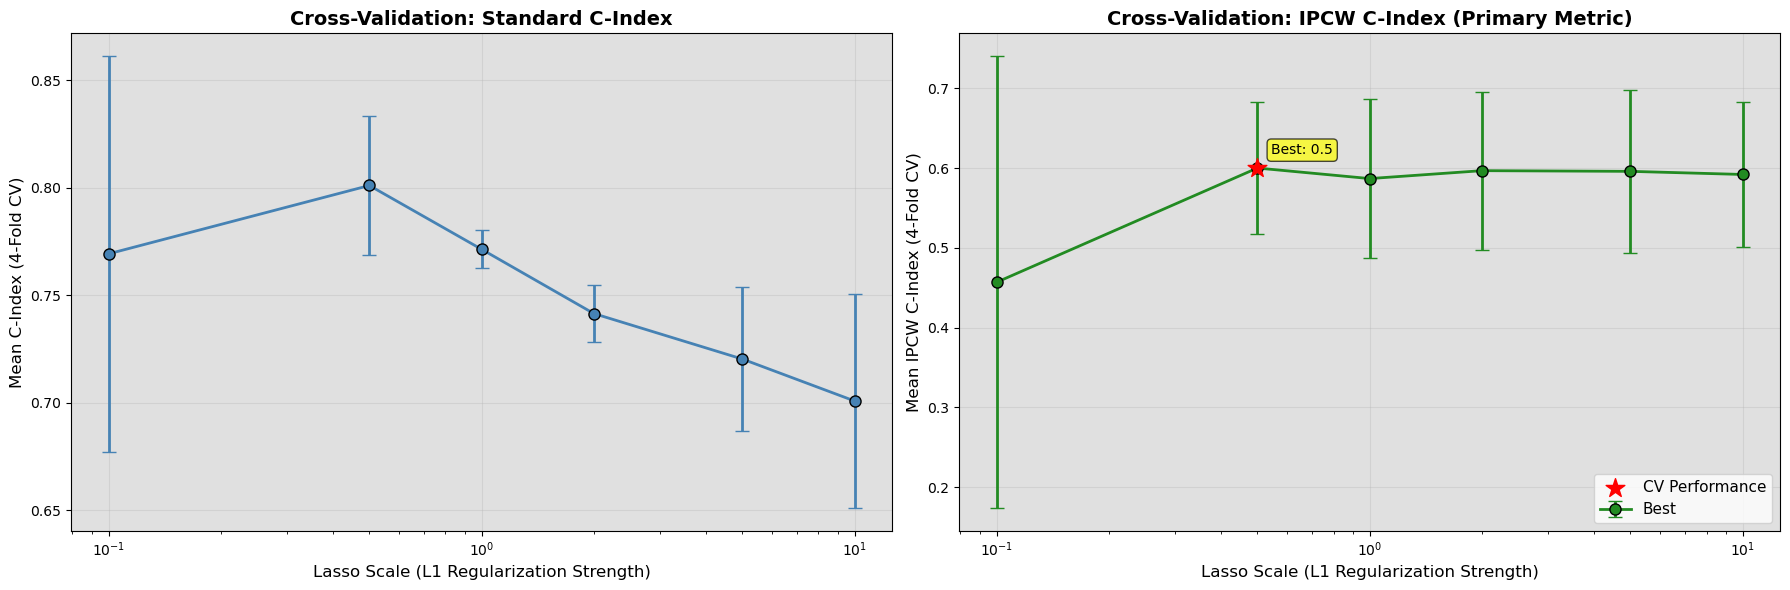

In [49]:
# Plot CV results (both C-Index and IPCW C-Index)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Standard C-Index
axes[0].errorbar(cv_summary['Lasso_Scale'], cv_summary['Mean_C_Index'], 
                yerr=cv_summary['Std_C_Index'], fmt='o-', capsize=5, 
                color='steelblue', markeredgecolor='black', linewidth=2, markersize=8)
axes[0].set_xscale('log')
axes[0].set_xlabel('Lasso Scale (L1 Regularization Strength)', fontsize=12)
axes[0].set_ylabel('Mean C-Index (4-Fold CV)', fontsize=12)
axes[0].set_title('Cross-Validation: Standard C-Index', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_facecolor('#e0e0e0')

# Plot 2: IPCW C-Index (primary metric)
axes[1].errorbar(cv_summary['Lasso_Scale'], cv_summary['Mean_IPCW_C_Index'], 
                yerr=cv_summary['Std_IPCW_C_Index'], fmt='o-', capsize=5, 
                color='forestgreen', markeredgecolor='black', linewidth=2, markersize=8)

# Mark best point
best_row = cv_summary[cv_summary['Lasso_Scale'] == best_lasso_scale].iloc[0]
axes[1].scatter(best_row['Lasso_Scale'], best_row['Mean_IPCW_C_Index'], 
               color='red', s=200, zorder=5, marker='*')
axes[1].annotate(f'Best: {best_lasso_scale}', 
                xy=(best_row['Lasso_Scale'], best_row['Mean_IPCW_C_Index']),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=10)

axes[1].set_xscale('log')
axes[1].set_xlabel('Lasso Scale (L1 Regularization Strength)', fontsize=12)
axes[1].set_ylabel('Mean IPCW C-Index (4-Fold CV)', fontsize=12)
axes[1].set_title('Cross-Validation: IPCW C-Index (Primary Metric)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(['CV Performance', 'Best'], fontsize=11)
axes[1].set_facecolor('#e0e0e0')

plt.tight_layout()
plt.show()

## Final model

Train with whatever `lasso_scale` came out of the CV above.

## L1 vs L2, what's actually different

| Regularization | Prior Distribution | Effect |
|----------------|-------------------|--------|
| **L2 (Ridge)** | Gaussian: $N(0, \sigma^2)$ | Shrinks coefficients smoothly |
| **L1 (Lasso)** | Laplace: $\text{Laplace}(0, b)$ | **Sets coefficients to exactly 0** |

Heavier tails plus a sharp peak at zero in the Laplace prior is what drives the sparsity.

In [50]:
class BayesianCoxLassoModel(nn.Module):
    """
    Bayesian Cox Model with Laplace (L1/Lasso) prior for feature selection
    
    Uses Laplace prior instead of Gaussian, which encourages sparse solutions.
    """
    
    def __init__(self, n_features, lasso_scale=1.0):
        super().__init__()
        
        self.n_features = n_features
        self.lasso_scale = lasso_scale  # Controls L1 penalty strength
        
        # Variational parameters (posterior approximation)
        self.coef_mean = nn.Parameter(torch.zeros(n_features))
        self.coef_logvar = nn.Parameter(torch.ones(n_features) * (-3))
    
    def forward(self, X, sample=True):
        """
        Forward pass: compute log hazard ratios
        
        Args:
            X: Features
            sample: If True, sample from posterior. If False, use mean (for evaluation)
        """
        if sample and self.training:
            # Sample coefficients using reparameterization trick (training)
            coef_std = torch.exp(0.5 * self.coef_logvar)
            eps = torch.randn_like(coef_std)
            coef = self.coef_mean + eps * coef_std
        else:
            # Use posterior mean (evaluation)
            coef = self.coef_mean
        
        # Compute log hazard: β^T X
        log_hazard = torch.matmul(X, coef)
        
        return log_hazard
    
    def l1_penalty(self):
        """
        L1 regularization penalty (Lasso)
        
        Approximates the Laplace prior by penalizing the L1 norm of coefficients.
        This encourages sparsity (many coefficients → 0).
        """
        # L1 norm of posterior mean (main sparsity-inducing term)
        l1_penalty = torch.sum(torch.abs(self.coef_mean)) / self.lasso_scale
        
        return l1_penalty
    
    def kl_divergence(self):
        """
        Additional KL term for variance (keeps variances reasonable)
        """
        coef_var = torch.exp(self.coef_logvar)
        # Penalty on variance to prevent explosion
        kl = 0.5 * torch.sum(coef_var - self.coef_logvar - 1)
        return kl
    
    def get_coefficients(self):
        """
        Get posterior mean and std of coefficients
        """
        mean = self.coef_mean.detach().cpu().numpy()
        std = torch.exp(0.5 * self.coef_logvar).detach().cpu().numpy()
        return mean, std

print("✓ BayesianCoxLassoModel class defined")

✓ BayesianCoxLassoModel class defined


In [51]:
def cox_partial_likelihood_loss(log_hazards, times, events):
    """
    Negative log partial likelihood for Cox model (Breslow method)
    """
    # Sort by time (descending)
    order = torch.argsort(times, descending=True)
    log_hazards = log_hazards[order]
    events = events[order]
    
    # Log-sum-exp for numerical stability
    log_cumsum_hazards = torch.logcumsumexp(log_hazards, dim=0)
    
    # Partial likelihood for events only
    log_likelihood = torch.sum(events * (log_hazards - log_cumsum_hazards))
    
    # Negative log likelihood (to minimize)
    loss = -log_likelihood
    
    return loss


def train_bayesian_cox_lasso(model, X_train, time_train, event_train,
                             X_val=None, time_val=None, event_val=None,
                             n_epochs=100, batch_size=128, learning_rate=0.01,
                             l1_weight=0.1, kl_weight=0.001,
                             early_stopping_patience=20):
    """
    Train Bayesian Cox model with L1 (Lasso) regularization
    
    Args:
        l1_weight: Strength of L1 penalty (higher = more sparsity)
        kl_weight: Strength of variance penalty (usually small)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    n_train = X_train.shape[0]
    n_batches = int(np.ceil(n_train / batch_size))
    
    train_losses = []
    val_cindices = []
    sparsity_ratios = []
    best_val_cindex = 0
    patience_counter = 0
    
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        
        # Shuffle data
        indices = torch.randperm(n_train)
        
        for batch_idx in range(n_batches):
            # Get batch
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_train)
            batch_indices = indices[start_idx:end_idx]
            
            X_batch = X_train[batch_indices]
            time_batch = time_train[batch_indices]
            event_batch = event_train[batch_indices]
            
            # Forward pass
            log_hazards = model(X_batch)
            
            # Cox loss (negative log likelihood)
            cox_loss = cox_partial_likelihood_loss(log_hazards, time_batch, event_batch)
            
            # L1 penalty (Lasso regularization)
            l1_penalty = model.l1_penalty()
            
            # KL divergence (variance control)
            kl_loss = model.kl_divergence()
            
            # Total loss
            loss = cox_loss + l1_weight * l1_penalty + kl_weight * kl_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / n_batches
        train_losses.append(avg_loss)
        
        # Track sparsity
        coef_mean, _ = model.get_coefficients()
        sparsity = np.mean(np.abs(coef_mean) < 0.01)  # % of coefficients near zero
        sparsity_ratios.append(sparsity)
        
        # Validation (use posterior mean for stability)
        if X_val is not None:
            model.eval()
            with torch.no_grad():
                # Use posterior mean (deterministic, no sampling)
                val_log_hazards = model(X_val, sample=False)
                val_risk_scores = val_log_hazards.cpu().numpy()
                
                # C-index
                val_cindex = concordance_index_censored(
                    event_val.cpu().numpy().astype(bool),
                    time_val.cpu().numpy(),
                    val_risk_scores
                )[0]
                val_cindices.append(val_cindex)
                
                # Early stopping
                if val_cindex > best_val_cindex:
                    best_val_cindex = val_cindex
                    patience_counter = 0
                    best_model_state = model.state_dict().copy()
                else:
                    patience_counter += 1
            
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, "
                      f"Val C-Index: {val_cindex:.4f}, Sparsity: {sparsity*100:.1f}%")
            
            if patience_counter >= early_stopping_patience:
                print(f"\n✓ Early stopping at epoch {epoch+1}")
                model.load_state_dict(best_model_state)
                break
        else:
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Sparsity: {sparsity*100:.1f}%")
    
    return train_losses, val_cindices, sparsity_ratios

print("✓ Training functions defined")

✓ Training functions defined


In [52]:
# Initialize model with best hyperparameter from CV
model = BayesianCoxLassoModel(
    n_features=X_train.shape[1],
    lasso_scale=best_lasso_scale  # Best value from cross-validation
)

print(f"Model initialized:")
print(f"  - Features: {X_train.shape[1]}")
print(f"  - Regularization: L1 (Lasso)")
print(f"  - Lasso scale: {best_lasso_scale} (selected via CV)")

Model initialized:
  - Features: 69
  - Regularization: L1 (Lasso)
  - Lasso scale: 0.5 (selected via CV)


In [53]:
# Train the model (NO EARLY STOPPING - view full training)
print("Training Bayesian Cox Model with Lasso Regularization...")
print("=" * 70)
print("NOTE: Early stopping disabled to view full training behavior")
print("=" * 70)

train_losses, val_cindices, sparsity_ratios = train_bayesian_cox_lasso(
    model,
    X_train_tensor, time_train_tensor, event_train_tensor,
    X_val=X_test_tensor,
    time_val=time_test_tensor,
    event_val=event_test_tensor,
    n_epochs=100,       # Reduced from 200 for faster viewing
    batch_size=128,
    learning_rate=0.001,
    l1_weight=0.1,
    kl_weight=0.001,
    early_stopping_patience=999  # Effectively disabled (will never trigger)
)

print("\n" + "=" * 70)
print("✓ Training completed!")
print(f"Final validation C-Index: {val_cindices[-1]:.4f}")
print(f"Best validation C-Index: {max(val_cindices):.4f}")
print(f"Final sparsity: {sparsity_ratios[-1]*100:.1f}% of coefficients near zero")

Training Bayesian Cox Model with Lasso Regularization...
NOTE: Early stopping disabled to view full training behavior
Epoch 10/100 - Loss: 7.2583, Val C-Index: 0.7503, Sparsity: 97.1%
Epoch 10/100 - Loss: 7.2583, Val C-Index: 0.7503, Sparsity: 97.1%
Epoch 20/100 - Loss: 7.0360, Val C-Index: 0.7554, Sparsity: 89.9%
Epoch 20/100 - Loss: 7.0360, Val C-Index: 0.7554, Sparsity: 89.9%
Epoch 30/100 - Loss: 8.1496, Val C-Index: 0.7247, Sparsity: 85.5%
Epoch 30/100 - Loss: 8.1496, Val C-Index: 0.7247, Sparsity: 85.5%
Epoch 40/100 - Loss: 9.4345, Val C-Index: 0.6146, Sparsity: 92.8%
Epoch 40/100 - Loss: 9.4345, Val C-Index: 0.6146, Sparsity: 92.8%
Epoch 50/100 - Loss: 7.2151, Val C-Index: 0.7743, Sparsity: 92.8%
Epoch 50/100 - Loss: 7.2151, Val C-Index: 0.7743, Sparsity: 92.8%
Epoch 60/100 - Loss: 8.2060, Val C-Index: 0.7697, Sparsity: 89.9%
Epoch 60/100 - Loss: 8.2060, Val C-Index: 0.7697, Sparsity: 89.9%
Epoch 70/100 - Loss: 7.3482, Val C-Index: 0.7579, Sparsity: 92.8%
Epoch 70/100 - Loss: 7.3

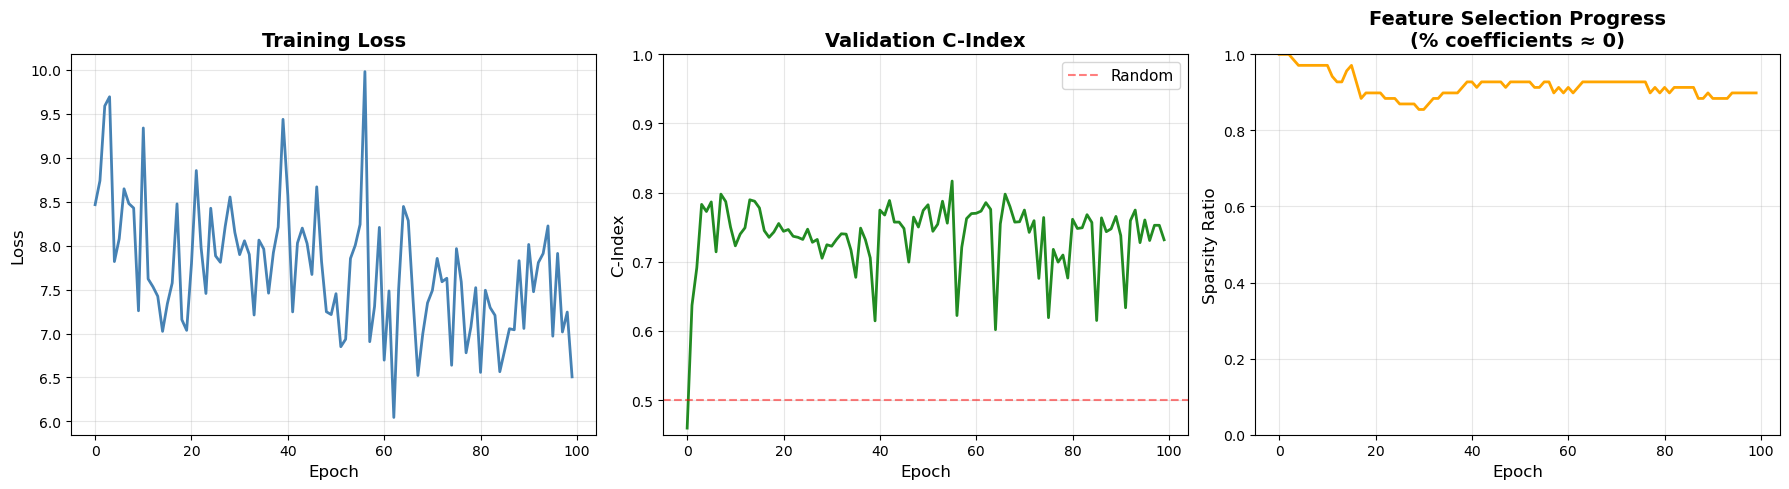

In [54]:
# Plot training progress
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss curve
axes[0].plot(train_losses, linewidth=2, color='steelblue')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training Loss', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# C-index curve
axes[1].plot(val_cindices, linewidth=2, color='forestgreen')
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('C-Index', fontsize=12)
axes[1].set_title('Validation C-Index', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0.45, 1.0])

# Sparsity evolution
axes[2].plot(sparsity_ratios, linewidth=2, color='orange')
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Sparsity Ratio', fontsize=12)
axes[2].set_title('Feature Selection Progress\n(% coefficients ≈ 0)', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## Model Evaluation and Feature Selection

In [55]:
# Get predictions with uncertainty
model.eval()
n_samples = 100  # Monte Carlo samples

train_predictions = []
test_predictions = []

with torch.no_grad():
    for _ in range(n_samples):
        train_log_hazards = model(X_train_tensor)
        train_predictions.append(train_log_hazards.cpu().numpy())
        
        test_log_hazards = model(X_test_tensor)
        test_predictions.append(test_log_hazards.cpu().numpy())

train_predictions = np.array(train_predictions)
test_predictions = np.array(test_predictions)

# Compute statistics
train_mean = train_predictions.mean(axis=0)
test_mean = test_predictions.mean(axis=0)

# C-Index
train_cindex = concordance_index_censored(
    event_train.astype(bool), time_train, train_mean
)[0]
test_cindex = concordance_index_censored(
    event_test.astype(bool), time_test, test_mean
)[0]

# Get coefficients
coef_mean, coef_std = model.get_coefficients()

# Count selected features
threshold = 0.01  # Consider coefficients < 0.01 as "zero"
selected = np.abs(coef_mean) >= threshold
n_selected = selected.sum()

print("=" * 70)
print("PERFORMANCE METRICS")
print("=" * 70)
print(f"\nConcordance Index (C-Index):")
print(f"  Training: {train_cindex:.4f}")
print(f"  Test:     {test_cindex:.4f}")
print(f"\nFeature Selection (Lasso):")
print(f"  Original features: {len(coef_mean)}")
print(f"  Selected features: {n_selected} ({n_selected/len(coef_mean)*100:.1f}%)")
print(f"  Removed features: {len(coef_mean) - n_selected} ({(len(coef_mean)-n_selected)/len(coef_mean)*100:.1f}%)")
print("=" * 70)

PERFORMANCE METRICS

Concordance Index (C-Index):
  Training: 0.8805
  Test:     0.7318

Feature Selection (Lasso):
  Original features: 69
  Selected features: 7 (10.1%)
  Removed features: 62 (89.9%)


In [56]:
# Analyze selected features
feature_names = X.columns.tolist()

# Create DataFrame with all coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef_mean,
    'Std': coef_std,
    'Lower_95CI': coef_mean - 1.96 * coef_std,
    'Upper_95CI': coef_mean + 1.96 * coef_std,
    'AbsCoef': np.abs(coef_mean),
    'Selected': np.abs(coef_mean) >= threshold
})

# Sort by absolute coefficient
coef_df = coef_df.sort_values('AbsCoef', ascending=False)

# Get selected features only
selected_df = coef_df[coef_df['Selected']].copy()

print("\n" + "=" * 90)
print(f"SELECTED FEATURES BY LASSO (|coefficient| >= {threshold})")
print("=" * 90)
print(f"{'Feature':<50s} | {'Coef':>8s} | {'Std':>7s} | {'95% CI':>20s}")
print("=" * 90)

for idx, row in selected_df.iterrows():
    feat_name = row['Feature'][:48]
    ci_str = f"[{row['Lower_95CI']:6.3f}, {row['Upper_95CI']:6.3f}]"
    print(f"{feat_name:<50s} | {row['Coefficient']:8.4f} | {row['Std']:7.4f} | {ci_str:>20s}")

print("=" * 90)
print(f"\nTotal selected: {len(selected_df)} / {len(coef_df)} features")


SELECTED FEATURES BY LASSO (|coefficient| >= 0.01)
Feature                                            |     Coef |     Std |               95% CI
Oestrogen receptor status at CB_1.0                |   0.2380 |  0.2048 |     [-0.163,  0.639]
Oestrogen receptor status at CB_2.0                |  -0.2108 |  0.2012 |     [-0.605,  0.183]
Conventional RT fraction_0.0                       |   0.0940 |  0.1970 |     [-0.292,  0.480]
Total administered dose                            |  -0.0326 |  0.1992 |     [-0.423,  0.358]
Radiotherapy (RT) performed                        |  -0.0273 |  0.2045 |     [-0.428,  0.373]
Adjuvant therapy with bio drugs                    |  -0.0132 |  0.1881 |     [-0.382,  0.355]
Conventional RT fraction_3.0                       |  -0.0100 |  0.1965 |     [-0.395,  0.375]

Total selected: 7 / 69 features


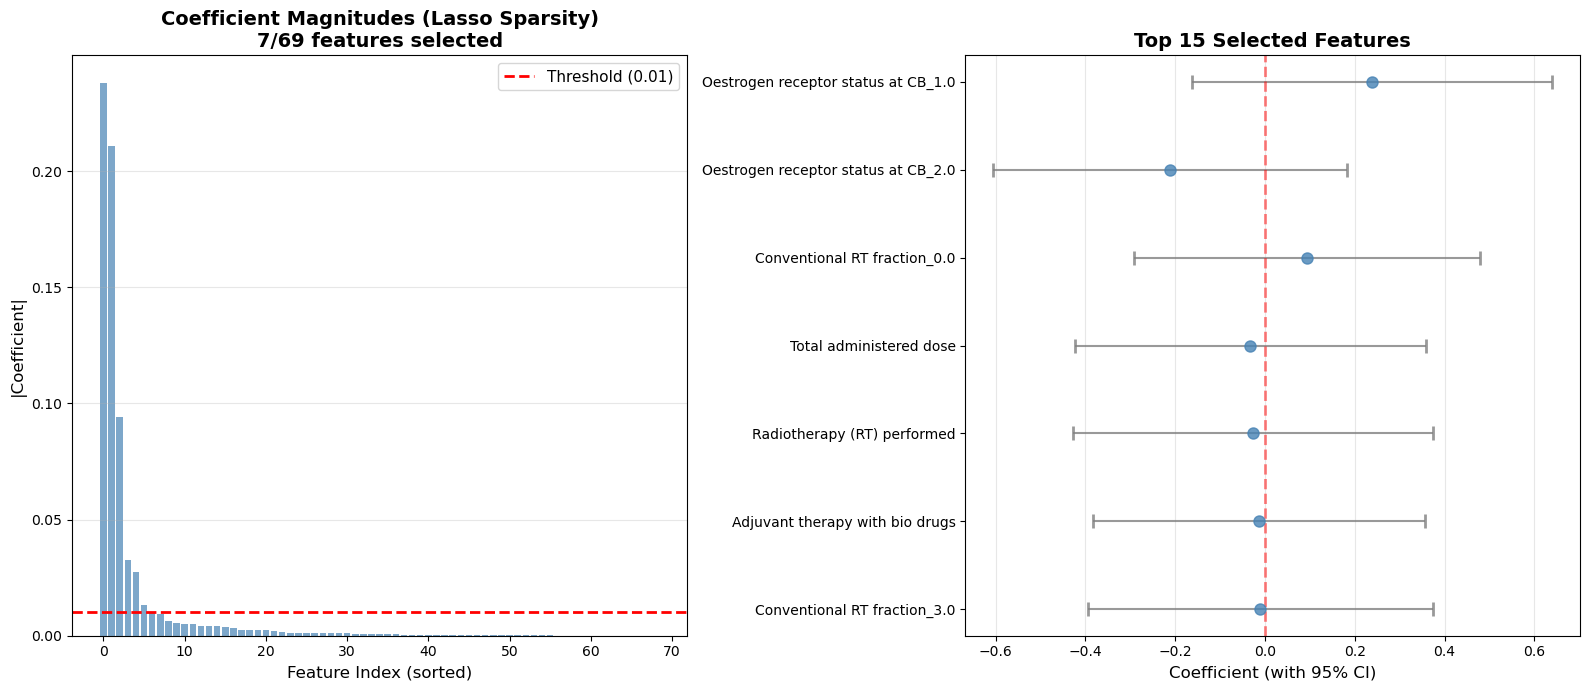

In [57]:
# Visualize selected features
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. All coefficients (to show sparsity)
coef_sorted = np.sort(np.abs(coef_mean))[::-1]
axes[0].bar(range(len(coef_sorted)), coef_sorted, color='steelblue', alpha=0.7)
axes[0].axhline(y=threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
axes[0].set_xlabel('Feature Index (sorted)', fontsize=12)
axes[0].set_ylabel('|Coefficient|', fontsize=12)
axes[0].set_title(f'Coefficient Magnitudes (Lasso Sparsity)\n{n_selected}/{len(coef_mean)} features selected',
                  fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 2. Selected features with uncertainty
plot_df = selected_df.head(15).iloc[::-1]  # Top 15, reversed for plotting

y_pos = np.arange(len(plot_df))
axes[1].errorbar(plot_df['Coefficient'], y_pos,
                 xerr=1.96*plot_df['Std'],
                 fmt='o', markersize=8, capsize=5, capthick=2,
                 color='steelblue', ecolor='gray', alpha=0.8)

axes[1].axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f[:40] for f in plot_df['Feature']], fontsize=10)
axes[1].set_xlabel('Coefficient (with 95% CI)', fontsize=12)
axes[1].set_title('Top 15 Selected Features', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

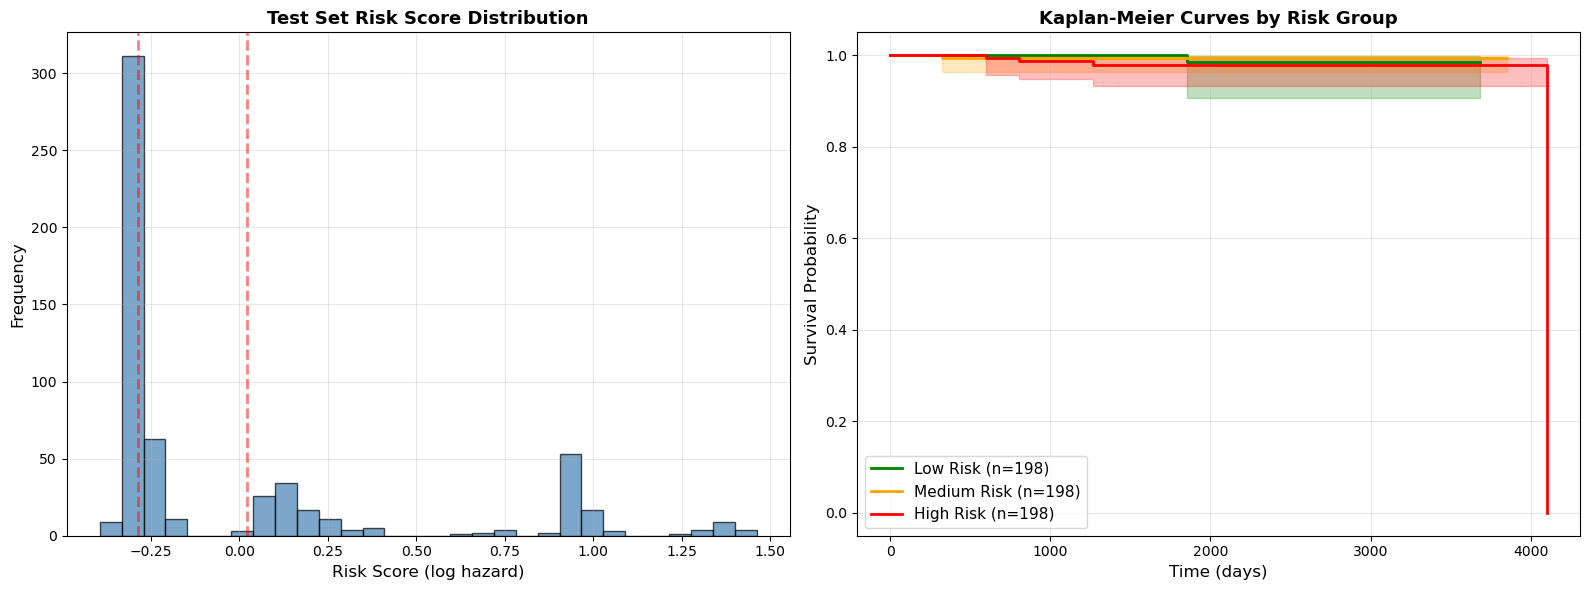


RISK GROUP COMPARISON (Log-Rank Test)
Low Risk vs Medium Risk: p-value = 0.9243
Low Risk vs High Risk: p-value = 0.3071
Medium Risk vs High Risk: p-value = 0.3721


In [58]:
# Risk stratification and Kaplan-Meier curves
risk_tertiles = np.percentile(test_mean, [33.33, 66.67])
risk_groups = np.digitize(test_mean, risk_tertiles)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Risk score distribution
axes[0].hist(test_mean, bins=30, alpha=0.7, color='steelblue', edgecolor='black')
for tertile in risk_tertiles:
    axes[0].axvline(tertile, color='red', linestyle='--', alpha=0.5, linewidth=2)
axes[0].set_xlabel('Risk Score (log hazard)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Test Set Risk Score Distribution', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. Kaplan-Meier curves by risk group
kmf = KaplanMeierFitter()
colors = ['green', 'orange', 'red']
labels = ['Low Risk', 'Medium Risk', 'High Risk']

for group in range(3):
    mask = risk_groups == group
    kmf.fit(time_test[mask], event_test[mask], label=f'{labels[group]} (n={mask.sum()})')
    kmf.plot_survival_function(ax=axes[1], ci_show=True, color=colors[group], linewidth=2)

axes[1].set_xlabel('Time (days)', fontsize=12)
axes[1].set_ylabel('Survival Probability', fontsize=12)
axes[1].set_title('Kaplan-Meier Curves by Risk Group', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11, loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Log-rank test
print("\n" + "=" * 70)
print("RISK GROUP COMPARISON (Log-Rank Test)")
print("=" * 70)
for i in range(3):
    for j in range(i+1, 3):
        mask_i = risk_groups == i
        mask_j = risk_groups == j
        result = logrank_test(
            time_test[mask_i], time_test[mask_j],
            event_test[mask_i], event_test[mask_j]
        )
        print(f"{labels[i]} vs {labels[j]}: p-value = {result.p_value:.4f}")
print("=" * 70)

## Lasso vs Ridge, summing up

Lasso drops irrelevant features outright (coefficients set to exactly 0), which gives a simpler, more interpretable model. Tends to help more when features >> samples, picks one representative out of a correlated group instead of splitting weight across all of them, and generally overfits less since fewer features stay active.

Tuning notes:
- `l1_weight` (L1 penalty strength): push up (0.2, 0.5) for more sparsity, down (0.05, 0.01) for less
- `lasso_scale` (model init): smaller = stronger regularization, larger = weaker
- pick whatever maximizes test C-Index, weighed against how much sparsity is actually wanted

| Use Lasso when: | Use Ridge when: |
|-----------------|----------------|
| Many irrelevant features | All features are relevant |
| Want feature selection | Want to keep all features |
| Features are correlated | Features are independent |
| Need interpretability | Need smooth shrinkage |